# WLASL-100 Dataset Exploration & Experimental Split

**Project:** Isolated word-level American Sign Language (ASL) recognition  
**Dataset:** WLASL (Word-Level American Sign Language)  
**Purpose:** Audit the metadata, select the canonical WLASL-100 subset, and create a reproducible signer-independent train/validation/test split.

## Research context

This project studies isolated sign classification. Each example is a video of one sign, and the target is its word-level gloss. This is not continuous sentence translation.

The central evaluation concern is signer leakage: recordings from the same signer must not appear in more than one experimental partition.

## Notebook outputs

This notebook creates the following files under `data/processed/WLASL100/`:

- `all_metadata.csv` — all selected instances with an `experimental_split` column
- `train_metadata.csv`, `val_metadata.csv`, `test_metadata.csv` — individual partitions
- `selected_classes.json` — canonical WLASL-100 class list, in official order
- `split_config.json` — split parameters and summary statistics

**Run this notebook from top to bottom.** It is designed to be reproducible and does not download or process videos.

## 1. Environment and paths

Only libraries needed for metadata exploration and splitting are imported here. Video-processing and MediaPipe dependencies belong in later notebooks.

The project root is detected from the notebook's working directory or its parent directories. If automatic detection fails, set `PROJECT_DIR` explicitly.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

# If your project is stored somewhere else, replace this with its absolute path.
# Based on the project layout used in this workflow, this is the expected location.
PROJECT_DIR = Path.home() / "sign-language-recognition"

metadata_relative_path = Path("WLASL") / "start_kit" / "WLASL_v0.3.json"

# Search the current working directory and its parents first. Then check the
# known project location. This works whether VS Code starts Jupyter from the
# project root, a notebook subfolder, or the WLASL repository folder.
search_roots = [Path.cwd(), *Path.cwd().parents, PROJECT_DIR]
metadata_path = None
project_dir = None

for root in search_roots:
    root = root.expanduser().resolve()
    possible_paths = [
        root / metadata_relative_path,
        root / "start_kit" / "WLASL_v0.3.json" if root.name == "WLASL" else None,
        root / "WLASL_v0.3.json" if root.name == "start_kit" else None,
    ]
    for candidate in possible_paths:
        if candidate is not None and candidate.is_file():
            metadata_path = candidate.resolve()
            if candidate.name == "WLASL_v0.3.json":
                if candidate.parent.name == "start_kit" and candidate.parent.parent.name == "WLASL":
                    project_dir = candidate.parent.parent.parent
                elif candidate.parent.name == "start_kit":
                    project_dir = candidate.parent.parent
                else:
                    project_dir = candidate.parent
            break
    if metadata_path is not None:
        break

if metadata_path is None:
    raise FileNotFoundError(
        "Could not find WLASL_v0.3.json.\n"
        f"Current notebook working directory: {Path.cwd()}\n"
        f"Also checked the expected project location: {PROJECT_DIR}\n\n"
        "Check that the WLASL repository is located at "
        "<project folder>/WLASL/start_kit/WLASL_v0.3.json. "
        "If your project folder is elsewhere, update PROJECT_DIR above."
    )

# The project root is the folder containing both WLASL/ and data/.
# If the metadata was found under a nested WLASL/start_kit directory, resolve it.
if project_dir is None:
    project_dir = metadata_path.parent.parent.parent

output_dir = project_dir / "data" / "processed" / "WLASL100"
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Notebook working directory: {Path.cwd()}")
print(f"Project root:               {project_dir}")
print(f"Metadata:                   {metadata_path}")
print(f"Output:                     {output_dir}")

Notebook working directory: /Users/sahilchauhan/Downloads
Project root:               /Users/sahilchauhan/sign-language-recognition
Metadata:                   /Users/sahilchauhan/sign-language-recognition/WLASL/start_kit/WLASL_v0.3.json
Output:                     /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100


## 2. Load and understand the original metadata

The WLASL metadata is hierarchical: each top-level entry is a gloss (class), containing multiple video instances. We first inspect the structure and then flatten it so each row represents one video instance.

In [2]:
with metadata_path.open("r", encoding="utf-8") as f:
    wlasl_data = json.load(f)

print(f"Gloss classes in metadata: {len(wlasl_data):,}")
print(f"Instances in first class ({wlasl_data[0]['gloss']}): "
      f"{len(wlasl_data[0]['instances']):,}")

display(pd.Series(wlasl_data[0]["instances"][0], name="Example instance"))

Gloss classes in metadata: 2,000
Instances in first class (book): 40


bbox                                     [385, 37, 885, 720]
fps                                                       25
frame_end                                                 -1
frame_start                                                1
instance_id                                                0
signer_id                                                118
source                                              aslbrick
split                                                  train
url             http://aslbricks.org/New/ASL-Videos/book.mp4
variation_id                                               0
video_id                                               69241
Name: Example instance, dtype: object

In [3]:
records = []

for class_entry in wlasl_data:
    gloss = class_entry["gloss"]
    for instance in class_entry["instances"]:
        records.append({
            "gloss": gloss,
            # Keep IDs as strings: some WLASL IDs contain leading zeros.
            "video_id": str(instance["video_id"]),
            "signer_id": instance.get("signer_id"),
            "split": instance.get("split"),
            "fps": instance.get("fps"),
            "frame_start": instance.get("frame_start"),
            "frame_end": instance.get("frame_end"),
            "source": instance.get("source"),
            "bbox": instance.get("bbox"),
            "url": instance.get("url"),
        })

df = pd.DataFrame(records)

print(f"Metadata instances: {len(df):,}")
print(f"Unique glosses:     {df['gloss'].nunique():,}")
print(f"Unique video IDs:   {df['video_id'].nunique():,}")
print(f"Unique signers:     {df['signer_id'].nunique():,}")
display(df.head())

Metadata instances: 21,083
Unique glosses:     2,000
Unique video IDs:   21,083
Unique signers:     119


,gloss,video_id,signer_id,split,fps,frame_start,frame_end,source,bbox,url
0,book,69241,118,train,25,1,-1,aslbrick,"[385, 37, 885, 720]",http://aslbricks.org/New/ASL-Videos/book.mp4
1,book,65225,90,train,25,1,-1,aslsignbank,"[190, 25, 489, 370]",https://aslsignbank.haskins.yale.edu/dictionar...
2,book,68011,110,train,25,1,-1,valencia-asl,"[262, 1, 652, 480]",https://www.youtube.com/watch?v=0UsjUE-TXns
3,book,68208,113,train,25,1,60,lillybauer,"[123, 19, 516, 358]",https://www.youtube.com/watch?v=1QOYOZ3g-aY
4,book,68012,109,train,25,1,-1,valencia-asl,"[95, 0, 1180, 720]",https://www.youtube.com/watch?v=aGtIHKEdCds


## 3. Full-dataset metadata audit

We check missing values, duplicate identifiers, split labels, and the distribution of examples per gloss. These checks describe the metadata; they do not establish that the underlying video files are available or decodable.

In [4]:
audit = pd.Series({
    "metadata_instances": len(df),
    "unique_glosses": df["gloss"].nunique(),
    "unique_video_ids": df["video_id"].nunique(),
    "unique_signers": df["signer_id"].nunique(),
    "duplicate_video_ids": int(df["video_id"].duplicated().sum()),
    "duplicate_gloss_video_pairs": int(
        df.duplicated(subset=["gloss", "video_id"]).sum()
    ),
})
display(audit.to_frame("value"))

print("Missing values by field:")
display(df.isna().sum().to_frame("missing"))

print("Official split distribution:")
display(df["split"].value_counts(dropna=False).rename_axis("split").to_frame("instances"))

print("FPS summary:")
display(df["fps"].describe())

,value
metadata_instances,21083
unique_glosses,2000
unique_video_ids,21083
unique_signers,119
duplicate_video_ids,0
duplicate_gloss_video_pairs,0


Missing values by field:


,missing
gloss,0
video_id,0
signer_id,0
split,0
fps,0
frame_start,0
frame_end,0
source,0
bbox,0
url,0


Official split distribution:


,instances
split,
train,14289
val,3916
test,2878


FPS summary:


count    21083.0
mean        25.0
std          0.0
min         25.0
25%         25.0
50%         25.0
75%         25.0
max         25.0
Name: fps, dtype: float64

Instances per gloss across the full metadata


,instances
count,2000.000000
mean,10.541500
std,3.547192
min,6.000000
25%,8.000000
50%,10.000000
75%,12.000000
max,40.000000


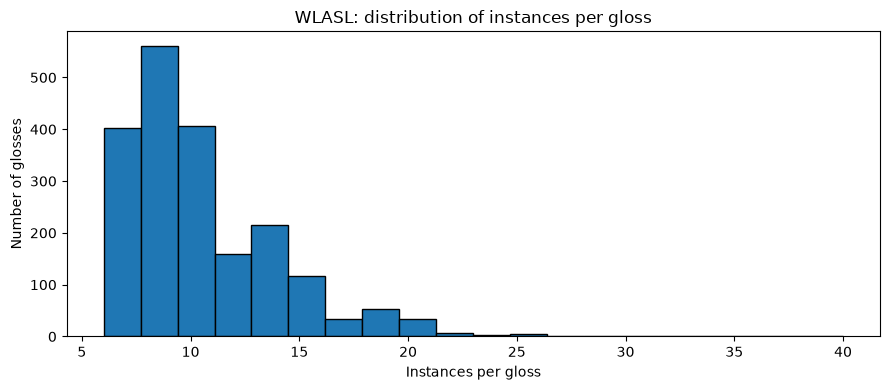

In [5]:
class_counts_full = df["gloss"].value_counts()

print("Instances per gloss across the full metadata")
display(class_counts_full.describe().to_frame("instances"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(class_counts_full, bins=20, edgecolor="black")
ax.set(
    title="WLASL: distribution of instances per gloss",
    xlabel="Instances per gloss",
    ylabel="Number of glosses",
)
fig.tight_layout()
plt.show()

## 4. Select the canonical WLASL-100 subset

The canonical WLASL-100 subset is defined by the **first 100 gloss entries in the official WLASL metadata**, not by recomputing the 100 most frequent glosses. Preserving this official ordering makes the subset definition reproducible and consistent with WLASL conventions.

In [6]:
official_100 = [entry["gloss"] for entry in wlasl_data[:100]]
assert len(official_100) == 100
assert len(set(official_100)) == 100

df_100 = df[df["gloss"].isin(official_100)].copy()

# Preserve official class order as an ordered categorical for consistent reporting.
df_100["gloss"] = pd.Categorical(
    df_100["gloss"], categories=official_100, ordered=True
)

print(f"Selected classes:   {df_100['gloss'].nunique():,}")
print(f"Selected instances: {len(df_100):,}")
print(f"Selected signers:   {df_100['signer_id'].nunique():,}")

Selected classes:   100
Selected instances: 2,038
Selected signers:   97


In [7]:
class_counts_100 = (
    df_100["gloss"].value_counts()
    .reindex(official_100)
    .rename("instances")
    .to_frame()
)
display(class_counts_100.describe())
print("Lowest-count classes:")
display(class_counts_100.sort_values("instances").head(10))

,instances
count,100.000000
mean,20.380000
std,3.280737
min,18.000000
25%,19.000000
50%,20.000000
75%,21.000000
max,40.000000


Lowest-count classes:


,instances
gloss,
thursday,18
africa,18
basketball,18
birthday,18
brown,18
but,18
cheat,18
city,18
cook,18


## 5. Audit the official splits for signer overlap

The original WLASL `train`, `val`, and `test` labels are useful dataset metadata, but they are not automatically signer-independent. We explicitly compare signer sets across the official partitions.

A positive overlap means the same signer occurs in both partitions.

In [8]:
official_signers = {
    split: set(df_100.loc[df_100["split"] == split, "signer_id"].dropna())
    for split in ["train", "val", "test"]
}

official_signer_counts = pd.Series(
    {split: len(signers) for split, signers in official_signers.items()},
    name="unique_signers",
)
display(official_signer_counts.to_frame())

overlap = pd.DataFrame(
    {
        "train": [
            len(official_signers["train"] & official_signers["train"]),
            len(official_signers["train"] & official_signers["val"]),
            len(official_signers["train"] & official_signers["test"]),
        ],
        "val": [
            len(official_signers["val"] & official_signers["train"]),
            len(official_signers["val"] & official_signers["val"]),
            len(official_signers["val"] & official_signers["test"]),
        ],
        "test": [
            len(official_signers["test"] & official_signers["train"]),
            len(official_signers["test"] & official_signers["val"]),
            len(official_signers["test"] & official_signers["test"]),
        ],
    },
    index=["train", "val", "test"],
)
print("Pairwise signer-set intersection counts:")
display(overlap)

,unique_signers
train,91
val,69
test,56


Pairwise signer-set intersection counts:


,train,val,test
train,91,64,52
val,64,69,50
test,52,50,56


## 6. Signer and class coverage analysis

A signer-independent split can be challenging because not every signer performs every gloss. We inspect (a) how many distinct glosses each signer contributes and (b) how many distinct signers contribute to each gloss. This helps explain why video counts may differ substantially from signer proportions after grouping.

In [9]:
signer_gloss = pd.crosstab(df_100["signer_id"], df_100["gloss"])
glosses_per_signer = (signer_gloss > 0).sum(axis=1).sort_values(ascending=False)
signers_per_gloss = (signer_gloss > 0).sum(axis=0).reindex(official_100)

print("Distinct glosses per signer:")
display(glosses_per_signer.describe().to_frame("glosses"))
print("Signers contributing to each gloss:")
display(signers_per_gloss.describe().to_frame("signers"))
print("Glosses with the fewest distinct signers:")
display(signers_per_gloss.sort_values().head(10).to_frame("signers"))

Distinct glosses per signer:


,glosses
count,97.000000
mean,15.474227
std,21.107904
min,1.000000
25%,3.000000
50%,7.000000
75%,15.000000
max,97.000000


Signers contributing to each gloss:


,signers
count,100.000000
mean,15.010000
std,2.022575
min,10.000000
25%,14.000000
50%,15.000000
75%,17.000000
max,21.000000


Glosses with the fewest distinct signers:


,signers
gloss,
tell,10
cool,11
paint,11
cheat,11
same,11
clothes,12
give,12
pizza,12
secretary,12


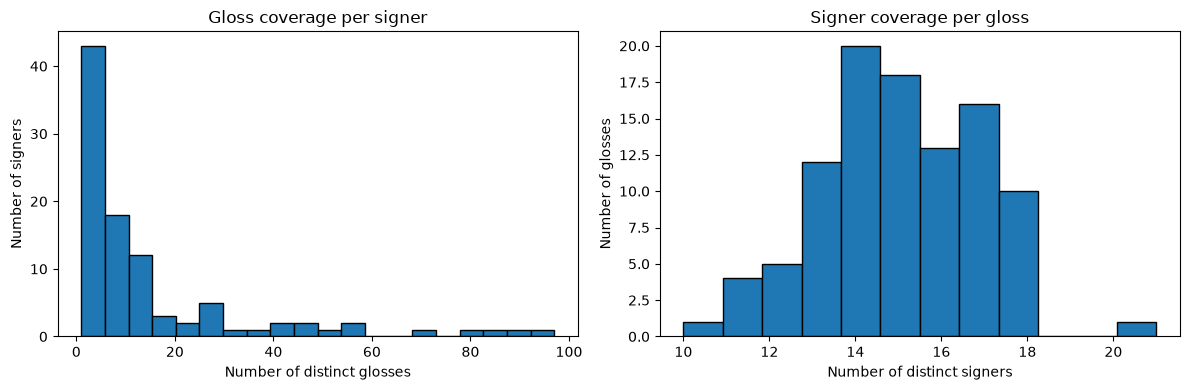

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(glosses_per_signer, bins=20, edgecolor="black")
axes[0].set(
    title="Gloss coverage per signer",
    xlabel="Number of distinct glosses",
    ylabel="Number of signers",
)

axes[1].hist(signers_per_gloss, bins=12, edgecolor="black")
axes[1].set(
    title="Signer coverage per gloss",
    xlabel="Number of distinct signers",
    ylabel="Number of glosses",
)

fig.tight_layout()
plt.show()

## 7. Construct a signer-independent experimental split

We use `GroupShuffleSplit` with `signer_id` as the grouping variable. This ensures that every recording from a signer is assigned to only one partition.

Target signer proportions are approximately:

- Train: 65%
- Validation: 15%
- Test: 20%

Because signers contribute unequal numbers of videos, the resulting **video proportions are not expected to match these percentages**.

### Split selection procedure

We evaluate a fixed range of random seeds and select the split with the best lexicographic score:

1. Number of classes represented in validation
2. Number of classes represented in test
3. Number of classes with at least two validation examples
4. Number of classes with at least two test examples
5. Number of classes represented in train

This is a split-selection heuristic, not model tuning: no model performance or test labels are used. The seed and resulting assignments are saved so all later models use exactly the same partitions.

In [11]:
ALL_CLASSES = official_100
N_SEEDS = 2000
TEST_SIZE = 0.20
VALIDATION_SIZE_WITHIN_TRAIN_VAL = 0.1875
SEED_OFFSET = 10_000

best_score = None
best_split = None

for seed in range(N_SEEDS):
    test_splitter = GroupShuffleSplit(
        n_splits=1, test_size=TEST_SIZE, random_state=seed
    )
    train_val_idx, test_idx = next(
        test_splitter.split(df_100, groups=df_100["signer_id"])
    )

    train_val_df = df_100.iloc[train_val_idx]
    test_candidate = df_100.iloc[test_idx]

    val_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_SIZE_WITHIN_TRAIN_VAL,
        random_state=seed + SEED_OFFSET,
    )
    train_idx, val_idx = next(
        val_splitter.split(
            train_val_df, groups=train_val_df["signer_id"]
        )
    )

    train_candidate = train_val_df.iloc[train_idx]
    val_candidate = train_val_df.iloc[val_idx]

    train_counts = train_candidate["gloss"].value_counts().reindex(
        ALL_CLASSES, fill_value=0
    )
    val_counts = val_candidate["gloss"].value_counts().reindex(
        ALL_CLASSES, fill_value=0
    )
    test_counts = test_candidate["gloss"].value_counts().reindex(
        ALL_CLASSES, fill_value=0
    )

    score = (
        int((val_counts > 0).sum()),
        int((test_counts > 0).sum()),
        int((val_counts >= 2).sum()),
        int((test_counts >= 2).sum()),
        int((train_counts > 0).sum()),
    )

    if best_score is None or score > best_score:
        best_score = score
        best_split = (
            train_candidate.copy(),
            val_candidate.copy(),
            test_candidate.copy(),
            seed,
        )

train_df, val_df, test_df, best_seed = best_split

print(f"Selected seed: {best_seed}")
print(f"Coverage score: {best_score}")

Selected seed: 165
Coverage score: (100, 100, 100, 100, 100)


## 8. Validate the experimental split

Before saving, we enforce the critical invariants:

- Partitions are mutually exclusive by signer.
- Every selected instance appears in exactly one partition.
- All 100 classes appear in each partition.
- At least two examples per class appear in validation and test.

The minimum training examples per class are reported rather than assumed.

In [12]:
split_frames = {
    "train": train_df,
    "validation": val_df,
    "test": test_df,
}

signer_sets = {
    name: set(part["signer_id"].dropna())
    for name, part in split_frames.items()
}

assert signer_sets["train"].isdisjoint(signer_sets["validation"])
assert signer_sets["train"].isdisjoint(signer_sets["test"])
assert signer_sets["validation"].isdisjoint(signer_sets["test"])

assert len(train_df) + len(val_df) + len(test_df) == len(df_100)
assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)

coverage = pd.DataFrame({
    name: part["gloss"].value_counts().reindex(ALL_CLASSES, fill_value=0)
    for name, part in split_frames.items()
})
coverage.index.name = "gloss"

assert (coverage["train"] > 0).all()
assert (coverage["validation"] >= 2).all()
assert (coverage["test"] >= 2).all()

print("Signer overlap (must all be zero):")
print({
    "train_validation": len(signer_sets["train"] & signer_sets["validation"]),
    "train_test": len(signer_sets["train"] & signer_sets["test"]),
    "validation_test": len(signer_sets["validation"] & signer_sets["test"]),
})

print("\nPartition summary:")
summary = pd.DataFrame({
    "instances": {name: len(part) for name, part in split_frames.items()},
    "signers": {name: len(signer_sets[name]) for name in split_frames},
    "classes": {name: part["gloss"].nunique() for name, part in split_frames.items()},
})
summary["instance_fraction"] = summary["instances"] / len(df_100)
display(summary)

print("Minimum examples per class:")
display(coverage.min().to_frame("minimum_count"))

Signer overlap (must all be zero):
{'train_validation': 0, 'train_test': 0, 'validation_test': 0}

Partition summary:


,instances,signers,classes,instance_fraction
train,1003,62,100,0.492149
validation,424,15,100,0.208047
test,611,20,100,0.299804


Minimum examples per class:


,minimum_count
train,5
validation,2
test,2


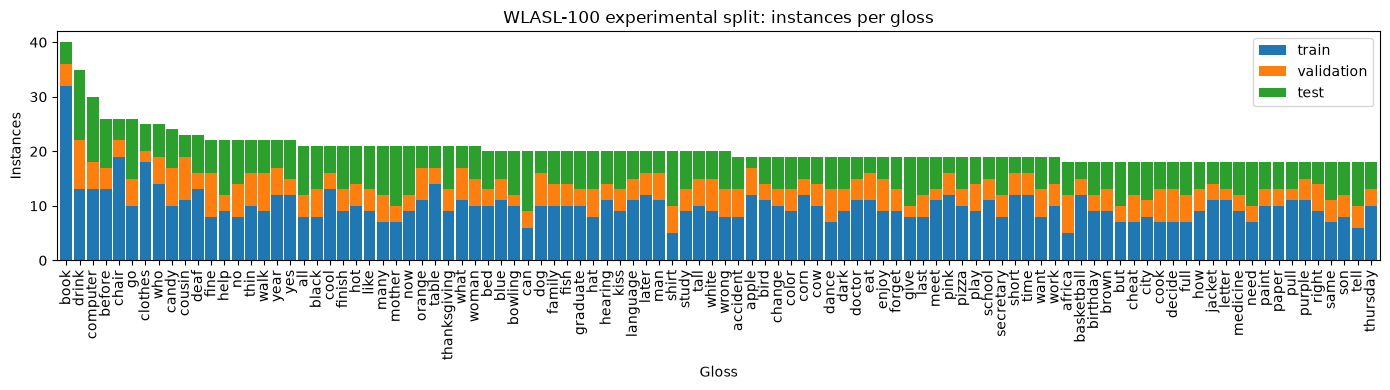

In [13]:
fig, ax = plt.subplots(figsize=(14, 4))
coverage[["train", "validation", "test"]].plot(
    kind="bar", stacked=True, width=0.9, ax=ax
)
ax.set(
    title="WLASL-100 experimental split: instances per gloss",
    xlabel="Gloss",
    ylabel="Instances",
)
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()

## 9. Save the frozen dataset definition and split

The split is saved once and should be reused unchanged for feature extraction, baseline models, deep learning, and subsequent comparisons. Do not regenerate it separately in later notebooks.

The combined metadata includes `experimental_split`, which is the authoritative partition label for this project. The original WLASL `split` column is retained separately for traceability.

In [14]:
# Add the experimental partition label and combine in a stable order.
combined_df = pd.concat(
    [
        train_df.assign(experimental_split="train"),
        val_df.assign(experimental_split="validation"),
        test_df.assign(experimental_split="test"),
    ],
    axis=0,
).copy()

# Restore gloss as a plain string for portable CSV output.
for frame in [train_df, val_df, test_df, combined_df]:
    frame["gloss"] = frame["gloss"].astype(str)

# Final checks on the combined output.
assert len(combined_df) == len(df_100)
assert combined_df["video_id"].nunique() == len(combined_df)
assert combined_df["experimental_split"].value_counts().to_dict() == {
    "train": len(train_df),
    "test": len(test_df),
    "validation": len(val_df),
}

train_df.to_csv(output_dir / "train_metadata.csv", index=False)
val_df.to_csv(output_dir / "val_metadata.csv", index=False)
test_df.to_csv(output_dir / "test_metadata.csv", index=False)
combined_df.to_csv(output_dir / "all_metadata.csv", index=False)

with (output_dir / "selected_classes.json").open("w", encoding="utf-8") as f:
    json.dump(official_100, f, indent=2)

config = {
    "dataset": "WLASL",
    "subset": "WLASL-100",
    "selection_rule": "first 100 gloss entries in official WLASL_v0.3.json",
    "number_of_classes": len(official_100),
    "number_of_instances": len(combined_df),
    "number_of_signers": int(combined_df["signer_id"].nunique()),
    "split_method": "GroupShuffleSplit",
    "group_column": "signer_id",
    "random_seed": int(best_seed),
    "seed_search": {
        "seeds_evaluated": N_SEEDS,
        "test_size": TEST_SIZE,
        "validation_size_within_train_val": VALIDATION_SIZE_WITHIN_TRAIN_VAL,
        "validation_test_class_minimum": 2,
        "selection_score": [
            "validation_classes_present",
            "test_classes_present",
            "validation_classes_with_at_least_2_instances",
            "test_classes_with_at_least_2_instances",
            "training_classes_present",
        ],
    },
    "signer_independent": True,
    "partitions": {
        name: {
            "instances": int(len(part)),
            "signers": int(len(signer_sets[name])),
            "classes": int(part["gloss"].nunique()),
            "instance_fraction": float(len(part) / len(combined_df)),
        }
        for name, part in split_frames.items()
    },
    "minimum_instances_per_class": {
        name: int(coverage[name].min())
        for name in ["train", "validation", "test"]
    },
}

with (output_dir / "split_config.json").open("w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved dataset definition and frozen split:")
for filename in [
    "all_metadata.csv",
    "train_metadata.csv",
    "val_metadata.csv",
    "test_metadata.csv",
    "selected_classes.json",
    "split_config.json",
]:
    path = output_dir / filename
    print(f"  {filename:<24} {path.stat().st_size:>10,} bytes")

print(f"\nOutput directory: {output_dir.resolve()}")

Saved dataset definition and frozen split:
  all_metadata.csv            250,829 bytes
  train_metadata.csv          119,374 bytes
  val_metadata.csv             49,964 bytes
  test_metadata.csv            67,881 bytes
  selected_classes.json         1,091 bytes
  split_config.json             1,251 bytes

Output directory: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100


## 10. Final reproducibility summary

This notebook has completed the metadata-level preparation of WLASL-100. It has **not** downloaded, decoded, cropped, or validated any videos. Those checks belong in the video-acquisition and preprocessing notebooks.

### Research safeguards

- Use the saved `experimental_split` for every experiment.
- Fit preprocessing transforms and feature normalisation on training data only.
- Use validation data for model selection.
- Keep the test set untouched until final evaluation.
- Report missing or unusable video instances transparently; do not silently change the class list or split.
- When moving to WLASL-300 or WLASL-2000, define and freeze a new subset-specific split and record its configuration.

### Dataset reference

Li, D., Rodriguez, C., Yu, X., & Li, H. (2020). *Word-level Deep Sign Language Recognition from Video: A New Large-scale Dataset and Methods Comparison*. IEEE Winter Conference on Applications of Computer Vision (WACV).